In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [2]:
X, y = make_regression(
    n_samples=500,
    n_features=10,
    n_informative=8,
    noise=20,
    random_state=42
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (500, 10)
Target shape: (500,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (350, 10)
Testing data: (150, 10)


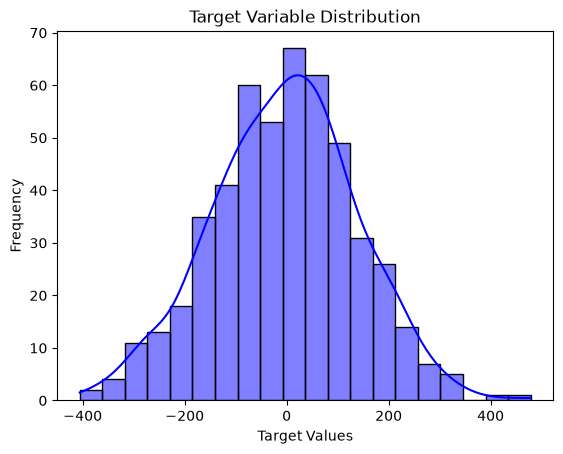

In [4]:
sns.histplot(y, kde=True, color="blue")

plt.title("Target Variable Distribution")
plt.xlabel("Target Values")
plt.ylabel("Frequency")
plt.show()

In [5]:
base_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

In [6]:
ada_reg = AdaBoostRegressor(
    estimator=base_model,
    n_estimators=200,
    learning_rate=0.1,
    random_state=42
)

In [7]:
ada_reg.fit(X_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.If ``None``, then the base estimator is:class:`~sklearn.tree.DecisionTreeRegressor` initialized with`max_depth=3`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeR...ndom_state=42)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",200
,"learning_rate learning_rate: float, default=1.0Weight applied to each regressor at each boosting iteration. A higherlearning rate increases the contribution of each regressor. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.In addition, it controls the bootstrap of the weights used to train the`estimator` at each boosting iteration.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'linear', 'square', 'exponential'}, default='linear'The loss function to use when updating the weights after eachboosting iteration.",'linear'
Name,Type,Value
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeRegressor,DecisionTreeR...ndom_state=42)
estimator_errors_ estimator_errors_: ndarray of floatsRegression error for each estimator in the boosted ensemble.,"ndarray[float64](200,)","[0.26,0.24,0.24,...,0.29,0.33,0.26]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](200,)","[0.1 ,0.12,0.11,...,0.09,0.07,0.1 ]"
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators.,list,"[DecisionTreeR...te=1608637542), DecisionTreeR...state=4466271), DecisionTreeR...ate=222580384), DecisionTreeR...te=1649112337), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](10,)","[0.16,0.01,0. ,...,0.01,0.22,0.13]"


In [8]:
y_pred = ada_reg.predict(X_test)

print("Actual values:", y_test[:10])
print("Predicted values:", y_pred[:10])

Actual values: [ 111.15071027 -114.97968624   33.86151294   25.7622751   -56.84583905
   57.46397183    5.38601955 -375.12951834   82.5467143  -298.98657489]
Predicted values: [ 1.69964193e+02 -4.29484014e+01 -6.63980087e-02  1.35322756e+02
 -6.63805490e+01  4.29740854e+01  6.15678846e+01 -1.02991626e+02
  6.38817852e+01 -1.90548635e+02]


In [12]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R2 Score:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

R2 Score: 0.6813887260271391
MAE: 65.91237555452547
MSE: 7228.1679860849
RMSE: 85.01863316994046


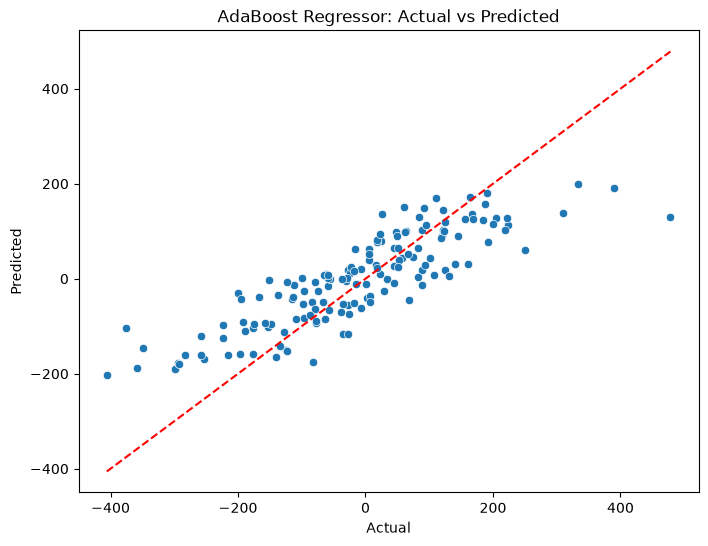

In [13]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=comparison,
    x="Actual",
    y="Predicted"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.title("AdaBoost Regressor: Actual vs Predicted")
plt.show()

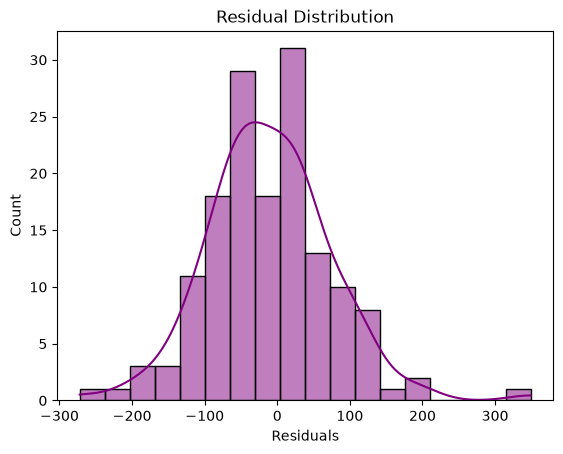

In [14]:
residuals = y_test - y_pred

sns.histplot(
    residuals,
    kde=True,
    color="purple"
)

plt.title("Residual Distribution")
plt.xlabel("Residuals")
plt.show()